In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

In [2]:
def f(x):
    return 3*x**2 - 4*x + 5

In [3]:
f(3)

20

In [5]:
xs=np.arange(-5,5,0.25)
xs

array([-5.  , -4.75, -4.5 , -4.25, -4.  , -3.75, -3.5 , -3.25, -3.  ,
       -2.75, -2.5 , -2.25, -2.  , -1.75, -1.5 , -1.25, -1.  , -0.75,
       -0.5 , -0.25,  0.  ,  0.25,  0.5 ,  0.75,  1.  ,  1.25,  1.5 ,
        1.75,  2.  ,  2.25,  2.5 ,  2.75,  3.  ,  3.25,  3.5 ,  3.75,
        4.  ,  4.25,  4.5 ,  4.75])

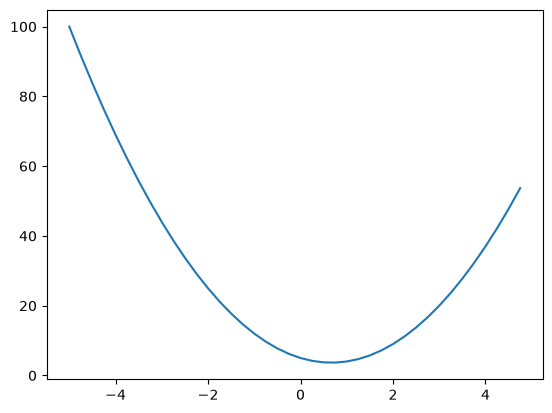

In [6]:
ys=f(xs)
plt.plot(xs,ys)

In [7]:
# derivative
# f′(x) = lim (h → 0) [f(x + h) − f(x)] / h 

In [14]:
h=0.000000001
x=-3.0
(f(x+h)-f(x))/h

-22.000001820288162

In [15]:
# let's get more complex noww
a= 2.0
b= -3.0
c= 10
d= a*b + c
print(d)

4.0


In [21]:
h = 0.0001

# inputs
a= 2.0
b= -3.0
c= 10


d1 = a*b + c
# a += h
b += h
# c += h
d2 = a*b + c
print('d1',d1)
print('d2',d2)            #d2 will give us sign of the slope i.e. if value goes down slope -ve and viceversa
print('slope',(d2-d1)/h)

d1 4.0
d2 4.00000001
slope 9.99999993922529e-05


In [179]:
class Value:
    
      
    def __init__(self, data, _children=(), _op='', label=''):
        self.data = data
        self.grad = 0.0
        self._backward = lambda: None
        self._prev = set(_children)
        self._op = _op
        self.label = label
    
    def __repr__(self):
        return f"Value(data={self.data})"
      
    def __add__(self, other):
        other = other if isinstance(other , Value) else Value(other)
        out = Value(self.data + other.data, (self, other), '+')

        def _backward():
            self.grad += 1.0 * out.grad
            other.grad += 1.0 * out.grad
        out._backward = _backward
        
        return out
    
    def __mul__(self, other):
        other = other if isinstance(other , Value) else Value(other)
        out = Value(self.data * other.data, (self, other), '*')

        def _backward():
            self.grad += other.data * out.grad
            other.grad += self.data * out.grad
            
        out._backward = _backward
        return out

    def __pow__(self ,other):
        assert isinstance(other ,(int, float)), "only supporting int/float powers for now"
        out = Value(self.data**other, (self,), f'**{other}')

        def _backward():
            self.grad += (other * self.data ** (other-1) ) * out.grad    #exercise :)
        out._backward = _backward
        return out

    def __rmul__(self,other):    # other * self
        return self * other

    def __truediv__(self,other):   # self / other
        return self * other**-1

    def __neg__(self):   # -self 
        return self * -1

    def __sub__(self ,other):    # self - other
        return self + (-other)
    
    def tanh(self):
        x = self.data
        t = (math.exp(2*x) - 1)/(math.exp(2*x) + 1)
        out = Value(t ,(self,),'tanh')

        def _backward():
            self.grad += (1 - t**2) * out.grad
            # other.grad = 
        out._backward =  _backward
        return out
    
    def exp(self):
        x = self.data
        out = Value(math.exp(x), (self,), 'exp')

        def _backward():
            self.grad += out.data * out.grad
        out._backward =  _backward
        return out

    def backward(self):
        
        topo = []
        visited = set()
        def build_topo(v):
            if v not in visited:
                visited.add(v)
                for child in v._prev:
                    build_topo(child)
                topo.append(v)
        build_topo(self)
        topo

        self.grad = 1.0
        for node in reversed(topo):
            node._backward()


a = Value(2.0, label='a')
b = Value(-3.0, label='b')
c = Value(10.0, label='c')
e = a*b; e.label = 'e'
d = e + c; d.label = 'd'
f = Value(-2.0, label='f')
L = d * f; L.label = 'L'
L

Value(data=-8.0)

In [180]:
a = Value(2.0)
b = Value(4.0)
# 2*a
# a/b
a-b

Value(data=-2.0)

In [73]:
d._prev

{Value(data=-6.0), Value(data=10.0)}

In [74]:
d._op

'+'

In [75]:
from graphviz import Digraph

def trace(root):
  # builds a set of all nodes and edges in a graph
  nodes, edges = set(), set()
  def build(v):
    if v not in nodes:
      nodes.add(v)
      for child in v._prev:
        edges.add((child, v))
        build(child)
  build(root)
  return nodes, edges

def draw_dot(root):
  dot = Digraph(format='svg', graph_attr={'rankdir': 'LR'}) # LR = left to right
  
  nodes, edges = trace(root)
  for n in nodes:
    uid = str(id(n))
    # for any value in the graph, create a rectangular ('record') node for it
    dot.node(name = uid, label = "{ %s | data %.4f | grad %.4f }" % (n.label, n.data, n.grad), shape='record')
    if n._op:
      # if this value is a result of some operation, create an op node for it
      dot.node(name = uid + n._op, label = n._op)
      # and connect this node to it
      dot.edge(uid + n._op, uid)

  for n1, n2 in edges:
    # connect n1 to the op node of n2
    dot.edge(str(id(n1)), str(id(n2)) + n2._op)

  return dot

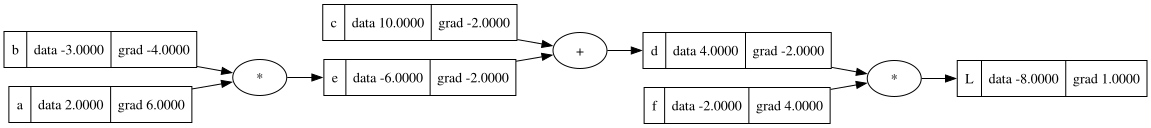

In [97]:
draw_dot(L)

In [ ]:
L = d * f
dL/dd =? f

(f(x+h)-f(x))/h
((d+h)*f - d*f)/h
(d*f + h*f - d*f)/h
(h*f)/h
f

In [96]:
a.grad = 6.0
b.grad = -4.0

In [93]:
def lol():
    h = 0.001
    a = Value(2.0, label='a')
    b = Value(-3.0, label='b')
    c = Value(10.0, label='c')
    e = a*b; e.label = 'e'
    d = e + c; d.label = 'd'
    f = Value(-2.0, label='f')
    L = d * f; L.label = 'L'
    L1 = L.data

    
    a = Value(2.0, label='a')
    b = Value(-3.0, label='b')
    c = Value(10.0, label='c')
    e = a*b; e.label = 'e'
    d = e + c; d.label = 'd'
    d.data += h
    f = Value(-2.0, label='f')
    L = d * f; L.label = 'L'
    L2 = L.data 

    print((L2 - L1) / h)

lol()

-2.000000000000668


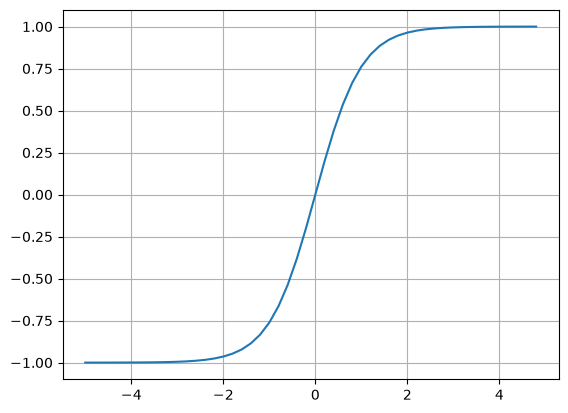

In [100]:
plt.plot(np.arange(-5,5,0.2), np.tanh(np.arange(-5,5,0.2)))
plt.grid()

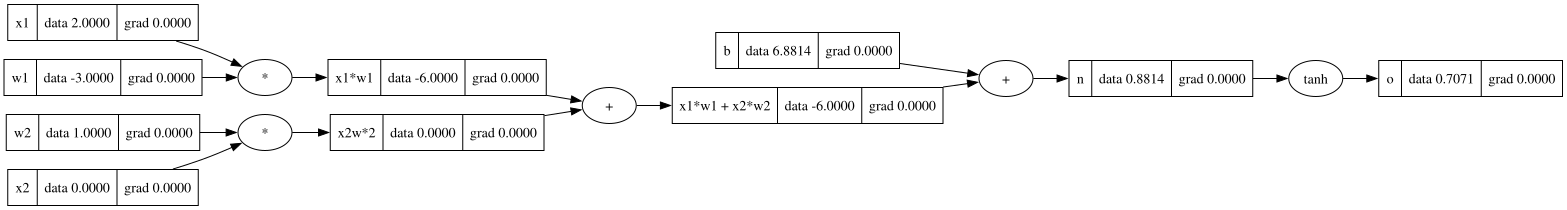

In [155]:
# inputs x1 , x2
x1 = Value(2.0, label = 'x1')
x2 = Value(0.0, label = 'x2')
# weights w1, w2
w1 = Value(-3.0, label = 'w1')
w2 = Value(1.0, label = 'w2')

# bias of neuron
b = Value(6.8813735870195432, label='b')
# x1w1 * x2w2 + b
x1w1 = x1*w1 ; x1w1.label = 'x1*w1'
x2w2 = x2*w2 ; x2w2.label = 'x2w*2'
x1w1x2w2 = x1w1 + x2w2; x1w1x2w2.label='x1*w1 + x2*w2'
n = x1w1x2w2 + b; n.label='n'
o = n.tanh() ;o.label='o'

# draw_dot(n)
draw_dot(o)


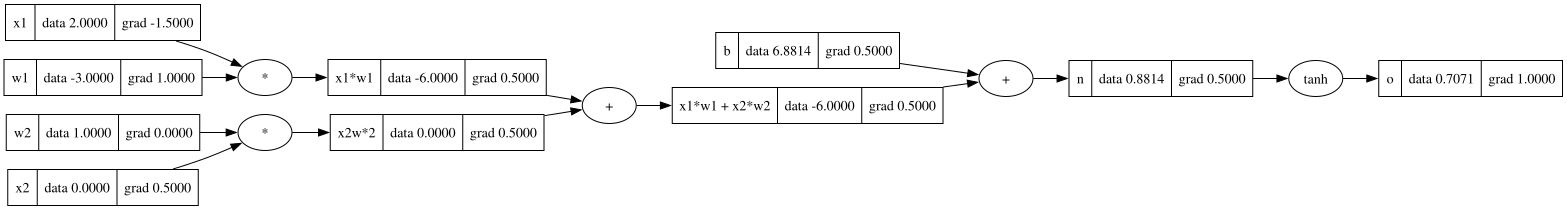

In [158]:
draw_dot(o)

In [157]:
o.backward()

In [152]:

topo = []
visited = set()
def build_topo(v):
    if v not in visited:
        visited.add(v)
        for child in v._prev:
            build_topo(child)
        topo.append(v)
build_topo(o)
topo


In [138]:
o.grad = 1.0

In [140]:
o._backward()

In [143]:
n._backward()

In [145]:
x1w1x2w2._backward()

In [147]:
x1w1._backward()
x2w2._backward()

In [ ]:
# o = tanh(n)
# do / dn = 1 - o**2

In [123]:
1 - o.data**2

0.4999999999999999

In [124]:
n.grad = 0.5

In [125]:
x1w1x2w2.grad = 0.5
b.grad = 0.5

In [126]:
x1w1.grad = 0.5
x2w2.grad = 0.5

In [128]:
x2.grad = w2.data * x2w2.grad
w2.grad = x2.data * x2w2.grad

In [129]:
x1.grad = w1.data * x1w1.grad
w1.grad = x1.data * x1w1.grad

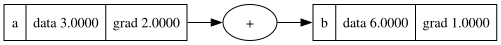

In [163]:
a = Value(3.0 ,label = 'a')
b = a+a ; b.label = 'b'
b.backward()

draw_dot(b)

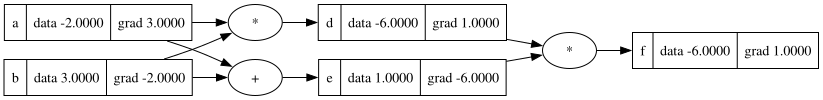

In [160]:
a = Value(-2.0 ,label = 'a')
b = Value(3.0 , label = 'b')
d = a*b ; d.label = 'd'
e = a+b ; e.label = 'e'
f = d*e ; f.label = 'f'

f.backward()

draw_dot(f)

In [ ]:







                                                                # OTHER HALF









In [165]:
a = Value(2.0)
a + 1

Value(data=3.0)

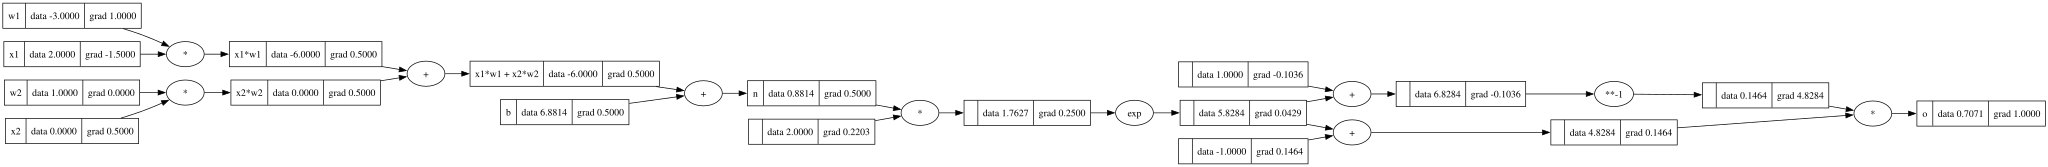

In [181]:
# inputs x1,x2
x1 = Value(2.0, label='x1')
x2 = Value(0.0, label='x2')
# weights w1,w2
w1 = Value(-3.0, label='w1')
w2 = Value(1.0, label='w2')
# bias of the neuron
b = Value(6.8813735870195432, label='b')
# x1*w1 + x2*w2 + b
x1w1 = x1*w1; x1w1.label = 'x1*w1'
x2w2 = x2*w2; x2w2.label = 'x2*w2'
x1w1x2w2 = x1w1 + x2w2; x1w1x2w2.label = 'x1*w1 + x2*w2'
n = x1w1x2w2 + b; n.label = 'n'
# ----
e = (2*n).exp()
o = (e - 1) / (e + 1)
# ----
o.label = 'o'
o.backward()
draw_dot(o)

In [182]:
# same thing using the pytorch and all the stuff

import torch

In [183]:
x1 = torch.Tensor([2.0]).double()                ; x1.requires_grad = True
x2 = torch.Tensor([0.0]).double()                ; x2.requires_grad = True
w1 = torch.Tensor([-3.0]).double()               ; w1.requires_grad = True
w2 = torch.Tensor([1.0]).double()                ; w2.requires_grad = True
b = torch.Tensor([6.8813735870195432]).double()  ; b.requires_grad = True
n = x1*w1 + x2*w2 + b
o = torch.tanh(n)

print(o.data.item())
o.backward()

print('---')
print('x2', x2.grad.item())
print('w2', w2.grad.item())
print('x1', x1.grad.item())
print('w1', w1.grad.item())

0.7071066904050358
---
x2 0.5000001283844369
w2 0.0
x1 -1.5000003851533106
w1 1.0000002567688737


In [201]:
import random

In [227]:
class Neuron:
  
  def __init__(self, nin):
    self.w = [Value(random.uniform(-1,1)) for _ in range(nin)]
    self.b = Value(random.uniform(-1,1))
  
  def __call__(self, x):
    # w * x + b
    act = sum((wi*xi for wi, xi in zip(self.w, x)), self.b)
    out = act.tanh()
    return out
  
  def parameters(self):
      return self.w + [self.b]

class Layer:
  
  def __init__(self, nin, nout):
    self.neurons = [Neuron(nin) for _ in range(nout)]
  
  def __call__(self, x):
    outs = [n(x) for n in self.neurons]
    return outs[0] if len(outs) == 1 else outs
  
  def parameters(self):
      
    return [p for neuron in self.neurons for p in neuron.parameters()]

class MLP:
  
  def __init__(self, nin, nouts):
    sz = [nin] + nouts
    self.layers = [Layer(sz[i], sz[i+1]) for i in range(len(nouts))]
  
  def __call__(self, x):
    for layer in self.layers:
      x = layer(x)
    return x
  
  def parameters(self):
    return [p for layer in self.layers for p in layer.parameters()]
    

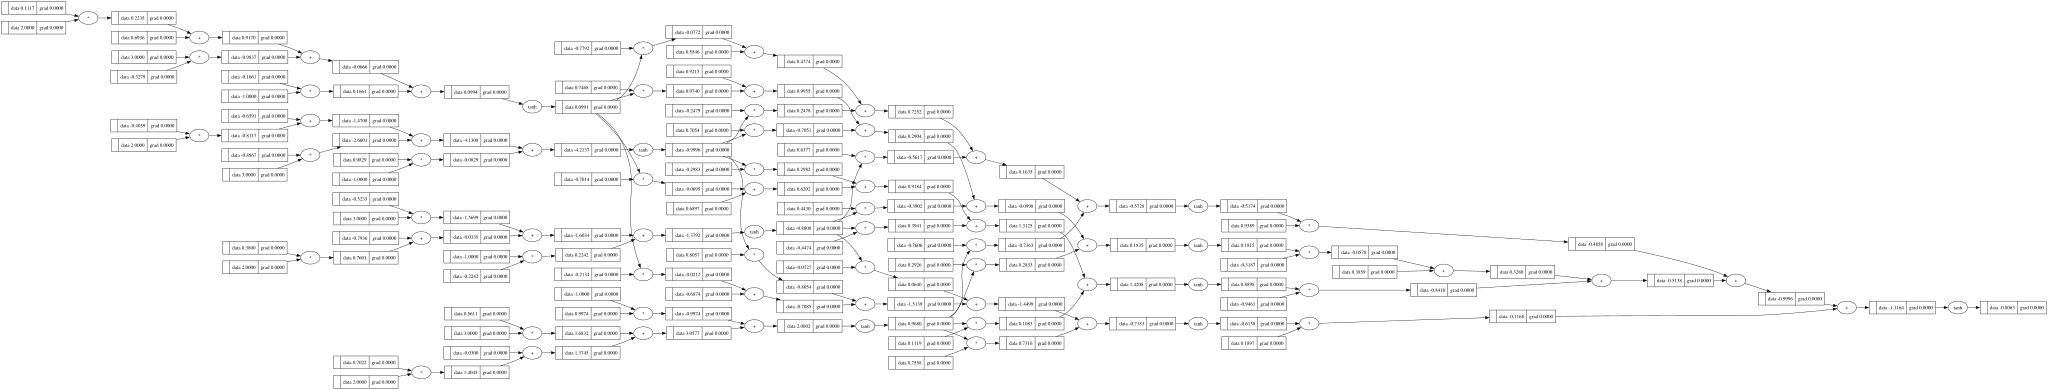

In [203]:
draw_dot(n(x))

In [315]:
x = [2.0 ,3.0 ,-1.0]
n = MLP(3 ,[4, 4, 1])
n(x)

Value(data=-0.7774525832728961)

In [316]:
n.parameters()

[Value(data=0.0004946407120014484),
 Value(data=0.2756358770550944),
 Value(data=-0.9045670641138686),
 Value(data=-0.907076504471547),
 Value(data=0.5914932309125092),
 Value(data=-0.5187556301193619),
 Value(data=-0.32535835511642763),
 Value(data=0.21939274333924286),
 Value(data=0.6955350909636782),
 Value(data=0.9592789312507091),
 Value(data=0.17988567838852432),
 Value(data=0.962098445736264),
 Value(data=0.07635307118842394),
 Value(data=-0.9521624167690355),
 Value(data=0.8534763449582135),
 Value(data=0.8245752089775416),
 Value(data=0.28814053701372355),
 Value(data=-0.25941612138614834),
 Value(data=-0.6140693664998271),
 Value(data=-0.8678507469871584),
 Value(data=0.7824184331046475),
 Value(data=-0.43984483910789085),
 Value(data=-0.4262260519145069),
 Value(data=-0.23373325597370398),
 Value(data=0.16137014078914103),
 Value(data=0.9175440031682498),
 Value(data=-0.30830690579480247),
 Value(data=-0.22353611750022573),
 Value(data=-0.3699975839361478),
 Value(data=0.617

In [317]:
xs = [
    [2.0 ,3.0 ,-1.0],
    [3.0 ,-1.0, 0.5],
    [0.5 ,1.0 ,1.0],
    [1.0 ,1.0 ,-1.0],
]
ys = [1.0 ,-1.0 ,-1.0 ,1.0] # desired targets
ypred = [n(x) for x in xs]
ypred

[Value(data=-0.7774525832728961),
 Value(data=-0.4326863894050566),
 Value(data=-0.6488322707342608),
 Value(data=-0.750634411045973)]

In [321]:
for k in range(20):
    # forward pass
    ypred = [n(x) for x in xs]
    loss = sum(((yout - ygt)**2 for ygt, yout in zip(ys, ypred)), Value(0.0))

    # backward pass
    for p in n.parameters():
        p.grad = 0.0
    loss.backward()

    # update
    for p in n.parameters():
        p.data += -0.05 * p.grad

    print(k, loss.data)
    

0 2.3657375199925764e-08
1 2.365721417989706e-08
2 2.3657053162024984e-08
3 2.3656892146377683e-08
4 2.365673113295071e-08
5 2.3656570121778132e-08
6 2.3656409112798406e-08
7 2.3656248105973013e-08
8 2.3656087101333805e-08
9 2.365592609894892e-08
10 2.365576509875461e-08
11 2.36556041007783e-08
12 2.365544310492658e-08
13 2.365528211139728e-08
14 2.3655121119990328e-08
15 2.365496013080573e-08
16 2.3654799143811604e-08
17 2.3654638159069455e-08
18 2.3654477176515533e-08
19 2.3654316196115745e-08


In [323]:
ypred

[Value(data=0.9999999997836844),
 Value(data=-0.9999900373628242),
 Value(data=-0.9998465234152826),
 Value(data=0.9999999997830192)]